# 04 – Analysis: comparing regex, Gemma 3 and MedGemma 1.5

Builds the tables and figures for the report from the logged eval runs. Nothing is run
through a model here; everything is read from `results/eval/`, so this notebook is light and
can run anywhere.

Contents:
1. Main results table, with 95 % bootstrap confidence intervals.
2. Paired comparison of the methods (McNemar's exact test).
3. F1 per Gleason score.
4. Error causes per method.
5. Confusion matrices.
6. Agreement between the methods, and the error lists for the qualitative analysis.

Two lists in the config come from reading the reports by hand (see "Findings so far" in
CLAUDE.md): the reports whose label no method can match, and the confirmed hallucinations.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import binomtest

sys.path.insert(0, ".")  # common.py lives next to this notebook
import common

In [ ]:
config = {
    # Display name -> logged run (results/<subset>/<run>). The order is the order in all tables
    # and figures, and each method keeps its color everywhere.
    "runs": {
        "Regex": "eval/v1",
        "Gemma 3": "eval/v2",
        "MedGemma 1.5": "eval/v3",
    },
    # Eval reports whose label cannot be matched by any method, found by reading the reports.
    # Patient ID -> reason.
    "unreachable": {
        **{pid: "label disagrees with report" for pid in [
            "TCGA-CH-5745", "TCGA-CH-5748", "TCGA-EJ-5502", "TCGA-TK-A8OK", "TCGA-V1-A8WN",
            "TCGA-V1-A9OA", "TCGA-V1-A9OH", "TCGA-V1-A9Z9", "TCGA-V1-A9ZG"]},
        **{pid: "label is the biopsy score" for pid in [
            "TCGA-V1-A9ZK", "TCGA-V1-A9ZR", "TCGA-V1-A9OY", "TCGA-V1-A9O7", "TCGA-V1-A9ZI",
            "TCGA-V1-A8MF"]},
        **{pid: "label not in report" for pid in ["TCGA-V1-A8X3", "TCGA-J9-A8CP"]},
        **{pid: "no Gleason score in report" for pid in ["TCGA-G9-A9S0", "TCGA-G9-A9S4"]},
    },
    # Hallucinations confirmed by hand: a pair that is not in the report, or a score for a
    # report without one. (The automatic flag also marks TCGA-J4-A83N, a false positive.)
    "hallucinations": {
        "Regex": [],
        "Gemma 3": ["TCGA-KK-A6E6"],
        "MedGemma 1.5": ["TCGA-CH-5751", "TCGA-CH-5752", "TCGA-EJ-7218", "TCGA-G9-A9S0", "TCGA-G9-A9S4"],
    },
    "n_bootstrap": 2000,  # resamples for the confidence intervals
    "seed": 13,
    "figures_dir": "figures",  # relative to the repo root
    "save_figures": True,
    # Colors: categorical slots 1-3 of the reference palette, 
    # one per method. Text uses ink colors, never the method colors.
    "method_colors": ["#2a78d6", "#eb6834", "#1baf7a"],
    "ink": {"primary": "#0b0b0b", "secondary": "#52514e", "grid": "#e4e3df"},
    "confusion_cmap": ["#ffffff", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"],
}

## Load the runs

In [3]:
methods = list(config["runs"])
colors = dict(zip(methods, config["method_colors"]))
ink = config["ink"]
figures_dir = common.ROOT / config["figures_dir"]
figures_dir.mkdir(exist_ok=True)

tables, scores, configs = {}, {}, {}
for method, run in config["runs"].items():
    subset, name = run.split("/")
    run_dir = common.RESULTS_DIR / subset
    tables[method] = pd.read_csv(run_dir / f"{name}.csv").set_index("patient_id")
    scores[method] = json.loads((run_dir / f"{name}_scores.json").read_text())
    configs[method] = json.loads((run_dir / f"{name}_config.json").read_text())

# All runs must cover the same reports, in the same order, for the paired comparisons
ids = tables[methods[0]].index
assert all(tables[m].index.equals(ids) for m in methods), "Runs cover different reports"
unreachable = ids.isin(list(config["unreachable"]))
print(f"{len(ids)} eval reports, {unreachable.sum()} with a label no method can match, "
      f"{(~unreachable).sum()} reachable")
for method in methods:
    c = configs[method]
    print(f"  {method:13s} {c['run']}  model={c['model_id']}  block_thinking={c.get('block_thinking')}")

416 eval reports, 19 with a label no method can match, 397 reachable
  Regex         v1  model=None  block_thinking=None
  Gemma 3       v2  model=google/gemma-3-4b-it  block_thinking=True
  MedGemma 1.5  v3  model=google/medgemma-1.5-4b-it  block_thinking=True


In [4]:
# Matplotlib style for all figures: thin, recessive axes and grid; text in ink colors
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 300,
    "font.size": 10,
    "axes.edgecolor": ink["secondary"],
    "axes.labelcolor": ink["primary"],
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": ink["grid"],
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "xtick.color": ink["secondary"],
    "ytick.color": ink["secondary"],
    "legend.frameon": False,
})


def save(fig, name):
    """Save a figure as PNG and PDF in the figures folder, if save_figures is on.

    Args:
        fig: the matplotlib figure.
        name: file name without extension.
    """
    if config["save_figures"]:
        for ext in ["png", "pdf"]:
            fig.savefig(figures_dir / f"{name}.{ext}", bbox_inches="tight")
        print(f"Saved {config['figures_dir']}/{name}.png and .pdf")

## 1. Main results

Accuracy and macro-F1 on the Gleason score, exact match on the pattern pair, and the answer
rates. The confidence intervals are percentile bootstrap intervals over reports (95 %).
"Reachable" leaves out the reports whose label no method can match.

In [5]:
def bootstrap_ci(values, n, seed):
    """95 % percentile bootstrap interval for the mean of a 0/1 array.

    Args:
        values: array of 0/1 (or booleans), one per report.
        n: number of resamples.
        seed: random seed.

    Returns:
        (low, high) of the interval.
    """
    rng = np.random.default_rng(seed)
    values = np.asarray(values, dtype=float)
    means = rng.choice(values, size=(n, len(values)), replace=True).mean(axis=1)
    return np.percentile(means, [2.5, 97.5])


def with_ci(values):
    """Format the mean of a 0/1 array with its bootstrap interval, e.g. '0.962 [0.943, 0.978]'."""
    low, high = bootstrap_ci(values, config["n_bootstrap"], config["seed"])
    return f"{np.mean(values):.3f} [{low:.3f}, {high:.3f}]"


rows = []
for method in methods:
    t, s = tables[method], scores[method]
    reach = t[~unreachable]
    rows.append({
        "Method": method,
        "Accuracy (score)": with_ci(t["correct_score"]),
        "Macro-F1": f"{s['macro_f1']:.3f}",
        "Pair exact match": with_ci(t["correct_pair"]),
        "Pair exact match, reachable": with_ci(reach["correct_pair"]),
        "Invalid": int((t["status"] == "invalid").sum()),
        "Not found": int((t["status"] == "not_found").sum()),
        "Hallucinations (checked)": len(config["hallucinations"][method]),
    })
main_table = pd.DataFrame(rows).set_index("Method")
if config["save_figures"]:
    main_table.to_csv(figures_dir / "main_table.csv")
main_table

,Accuracy (score),Macro-F1,Pair exact match,"Pair exact match, reachable",Invalid,Not found,Hallucinations (checked)
Method,,,,,,,
Regex,"0.928 [0.904, 0.950]",0.858,"0.892 [0.861, 0.921]","0.935 [0.909, 0.960]",0,4,0
Gemma 3,"0.945 [0.923, 0.964]",0.931,"0.923 [0.897, 0.947]","0.967 [0.947, 0.982]",7,2,1
MedGemma 1.5,"0.962 [0.942, 0.978]",0.915,"0.938 [0.913, 0.959]","0.982 [0.967, 0.992]",1,0,5


## 2. Paired comparison

All methods see the same reports, so they are compared report by report with McNemar's
exact test: only the reports where exactly one of the two methods is right count. The test
is the exact binomial test on those discordant reports.

In [6]:
def mcnemar(a, b, column):
    """McNemar's exact test between two methods on one 0/1 column.

    Args:
        a, b: method names.
        column: "correct_pair" or "correct_score".

    Returns:
        dict with the number of reports only a / only b got right, and the two-sided p-value.
    """
    x, y = tables[a][column], tables[b][column]
    only_a, only_b = int((x & ~y).sum()), int((~x & y).sum())
    p = binomtest(only_a, only_a + only_b).pvalue if only_a + only_b else 1.0
    return {"only A right": only_a, "only B right": only_b, "p": round(p, 4)}


pairs = [("MedGemma 1.5", "Gemma 3"), ("MedGemma 1.5", "Regex"), ("Gemma 3", "Regex")]
paired = pd.DataFrame([
    {"A": a, "B": b, "measure": measure, **mcnemar(a, b, column)}
    for a, b in pairs
    for measure, column in [("pattern pair", "correct_pair"), ("score", "correct_score")]
])
if config["save_figures"]:
    paired.to_csv(figures_dir / "paired_tests.csv", index=False)
paired

,A,B,measure,only A right,only B right,p
0,MedGemma 1.5,Gemma 3,pattern pair,10,4,0.1796
1,MedGemma 1.5,Gemma 3,score,10,3,0.0923
2,MedGemma 1.5,Regex,pattern pair,24,5,0.0005
3,MedGemma 1.5,Regex,score,18,4,0.0043
4,Gemma 3,Regex,pattern pair,22,9,0.0294
5,Gemma 3,Regex,score,15,8,0.2100


## 3. F1 per Gleason score

The class sizes are under the axis: score 10 has only 4 reports, so its F1 moves a lot
with a single report.

Saved figures/f1_per_score.png and .pdf


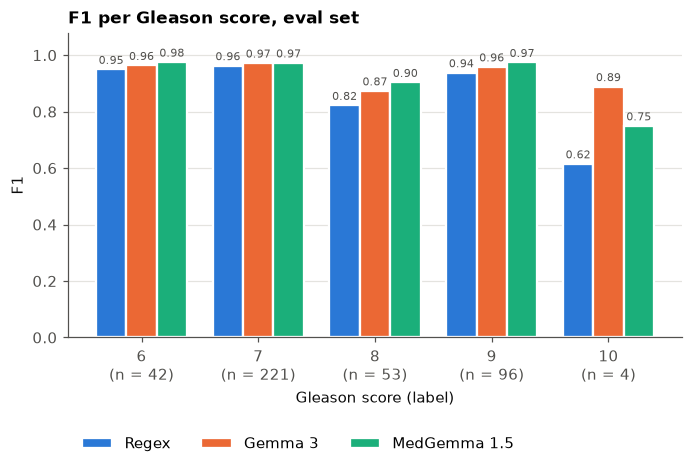

In [7]:
classes = list(scores[methods[0]]["f1_per_score"])
counts = tables[methods[0]]["label_score"].value_counts()
x = np.arange(len(classes))
width = 0.26

fig, ax = plt.subplots(figsize=(7.2, 3.6))
for i, method in enumerate(methods):
    f1 = [scores[method]["f1_per_score"][c] for c in classes]
    # A 2px white edge keeps a gap between neighbouring bars
    bars = ax.bar(x + (i - 1) * width, f1, width, color=colors[method], label=method,
                  edgecolor="white", linewidth=1.5)
    for bar, value in zip(bars, f1):
        ax.text(bar.get_x() + bar.get_width() / 2, value + 0.01, f"{value:.2f}",
                ha="center", va="bottom", fontsize=7, color=ink["secondary"])
ax.set_xticks(x, [f"{c}\n(n = {counts[int(c)]})" for c in classes])
ax.set_xlabel("Gleason score (label)")
ax.set_ylabel("F1")
ax.set_ylim(0, 1.08)
ax.set_title("F1 per Gleason score, eval set")
ax.legend(ncol=3, loc="upper left", bbox_to_anchor=(0, -0.28))
save(fig, "f1_per_score")
plt.show()

## 4. Error causes

Every wrong pattern pair is put in one category, checked in this order:
1. **Hallucination**: confirmed by hand (a pair not in the report, or a score for a report without one).
2. **Invalid answer**: unparseable or impossible (e.g. the total put in "primary").
3. **Label not matchable**: the report disagrees with the label, the label is the biopsy score, or the report has no score.
4. **Wrong score chosen / other**: the rest, mostly the wrong one of several scores in the report.

In [8]:
def error_cause(method, patient_id, row):
    """Return the error category of one wrong answer (see the list above)."""
    if patient_id in config["hallucinations"][method]:
        return "Hallucination"
    if row["status"] == "invalid":
        return "Invalid answer"
    if patient_id in config["unreachable"]:
        return "Label not matchable"
    return "Wrong score chosen / other"


causes = ["Label not matchable", "Wrong score chosen / other", "Invalid answer", "Hallucination"]
error_counts = pd.DataFrame(0, index=causes, columns=methods)
for method in methods:
    t = tables[method]
    for patient_id, row in t[~t["correct_pair"]].iterrows():
        error_counts.loc[error_cause(method, patient_id, row), method] += 1
error_counts.loc["Total wrong pairs"] = error_counts.sum()
if config["save_figures"]:
    error_counts.to_csv(figures_dir / "error_causes.csv")
print(error_counts)

                            Regex  Gemma 3  MedGemma 1.5
Label not matchable            19       19            17
Wrong score chosen / other     26        5             3
Invalid answer                  0        7             1
Hallucination                   0        1             5
Total wrong pairs              45       32            26


Saved figures/error_causes.png and .pdf


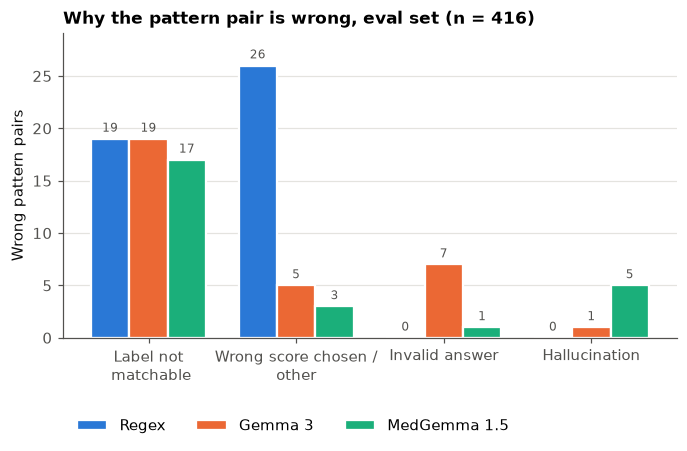

In [9]:
counts_plot = error_counts.loc[causes]
x = np.arange(len(causes))
fig, ax = plt.subplots(figsize=(7.2, 3.6))
for i, method in enumerate(methods):
    values = counts_plot[method].values
    bars = ax.bar(x + (i - 1) * width, values, width, color=colors[method], label=method,
                  edgecolor="white", linewidth=1.5)
    for bar, value in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width() / 2, value + 0.4, str(value),
                ha="center", va="bottom", fontsize=8, color=ink["secondary"])
ax.set_xticks(x, [c.replace(" / ", " /\n").replace("Label not", "Label not\n") for c in causes])
ax.set_ylabel("Wrong pattern pairs")
ax.set_ylim(0, counts_plot.values.max() * 1.12)
ax.set_title(f"Why the pattern pair is wrong, eval set (n = {len(ids)})")
ax.legend(ncol=3, loc="upper left", bbox_to_anchor=(0, -0.22))
save(fig, "error_causes")
plt.show()

## 5. Confusion matrices

Rows: the label's Gleason score. Columns: the predicted score, with "not found" and "invalid"
as their own columns. The color is the share of the row, so the small classes are visible too;
the numbers are counts.

Saved figures/confusion_matrices.png and .pdf


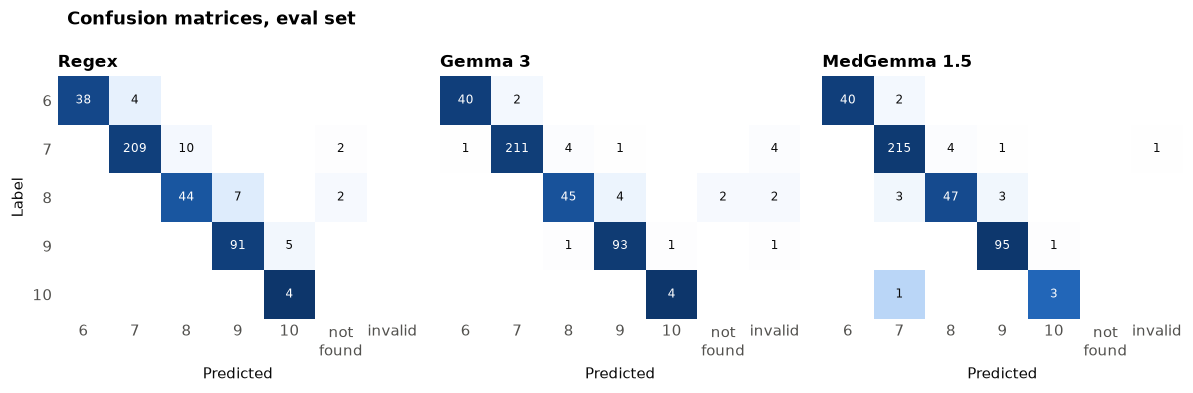

In [10]:
from matplotlib.colors import LinearSegmentedColormap

cmap = LinearSegmentedColormap.from_list("blue_ramp", config["confusion_cmap"])
true_classes = [int(c) for c in classes]
pred_columns = [str(c) for c in true_classes] + ["not_found", "invalid"]

fig, axes = plt.subplots(1, len(methods), figsize=(11, 3.6), sharey=True)
for ax, method in zip(axes, methods):
    matrix = pd.DataFrame(scores[method]["confusion_matrix"]).T.reindex(
        index=[str(c) for c in true_classes], columns=pred_columns).fillna(0).astype(int)
    share = matrix.div(matrix.sum(axis=1), axis=0)
    ax.imshow(share.values, cmap=cmap, vmin=0, vmax=1, aspect="auto")
    for (r, c), value in np.ndenumerate(matrix.values):
        if value:
            # Dark text on light cells, white text on dark cells
            ax.text(c, r, str(value), ha="center", va="center", fontsize=8,
                    color="white" if share.values[r, c] > 0.55 else ink["primary"])
    ax.set_xticks(range(len(pred_columns)), [p.replace("not_found", "not\nfound") for p in pred_columns])
    ax.set_yticks(range(len(true_classes)), true_classes)
    ax.set_title(method)
    ax.set_xlabel("Predicted")
    ax.grid(False)
    ax.spines[:].set_visible(False)
    ax.tick_params(length=0)
axes[0].set_ylabel("Label")
fig.suptitle("Confusion matrices, eval set", x=0.06, ha="left", fontweight="bold")
fig.tight_layout()
save(fig, "confusion_matrices")
plt.show()

## 6. Agreement and error lists

How many reports each combination of methods gets right (pattern pair), and the wrong
answers of each method with the label, for the qualitative error analysis.

In [11]:
right = pd.DataFrame({m: tables[m]["correct_pair"] for m in methods})
agreement = (right.apply(lambda r: " + ".join(m for m in methods if r[m]) or "none", axis=1)
             .value_counts().rename("reports").to_frame())
agreement.index.name = "Right (pattern pair)"
agreement

,reports
Right (pattern pair),
Regex + Gemma 3 + MedGemma 1.5,359
Gemma 3 + MedGemma 1.5,21
none,20
Regex + MedGemma 1.5,7
Regex + Gemma 3,3
MedGemma 1.5,3
Regex,2
Gemma 3,1


In [12]:
error_rows = []
for method in methods:
    t = tables[method]
    for patient_id, row in t[~t["correct_pair"]].iterrows():
        error_rows.append({
            "method": method,
            "patient_id": patient_id,
            "label": f"{row['label_primary']}+{row['label_secondary']}",
            "predicted": "not found" if row["status"] == "not_found"
                         else f"{row['pred_primary']}+{row['pred_secondary']}".replace(".0", ""),
            "cause": error_cause(method, patient_id, row),
            "unreachable reason": config["unreachable"].get(patient_id, ""),
        })
errors = pd.DataFrame(error_rows)
if config["save_figures"]:
    errors.to_csv(figures_dir / "errors.csv", index=False)
errors[errors["method"] != "Regex"].sort_values(["cause", "method"])

,method,patient_id,label,predicted,cause,unreachable reason
56,Gemma 3,TCGA-KK-A6E6,4+5,3+5,Hallucination,
79,MedGemma 1.5,TCGA-CH-5751,5+5,3+4,Hallucination,
80,MedGemma 1.5,TCGA-CH-5752,4+4,3+4,Hallucination,
83,MedGemma 1.5,TCGA-EJ-7218,3+4,5+4,Hallucination,
84,MedGemma 1.5,TCGA-G9-A9S0,4+4,3+4,Hallucination,no Gleason score in report
85,MedGemma 1.5,TCGA-G9-A9S4,4+4,3+4,Hallucination,no Gleason score in report
49,Gemma 3,TCGA-EJ-5503,5+3,8+3,Invalid answer,
53,Gemma 3,TCGA-J9-A8CK,4+5,9+7,Invalid answer,
55,Gemma 3,TCGA-KK-A6E2,3+4,7+4,Invalid answer,
57,Gemma 3,TCGA-KK-A7AV,3+4,7+4,Invalid answer,
